<a href="https://colab.research.google.com/github/leila-megdiche/Auspify-ML-Internship/blob/main/01_recommendation_c.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 1: Netflix Content Recommendation System

**Goal:** suggest Netflix titles similar to a title the user likes, using content-based filtering.

**Approach (follows the 5 steps of the task):**
1. Prepare content features (genres, director, country, type)
2. Convert the text into numbers with TF-IDF
3. Compute similarity between titles with cosine similarity
4. Generate recommendations for selected titles
5. Evaluate the quality of the recommendations

## 0. Load the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from difflib import get_close_matches
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Works in Google Colab (upload window) and on a normal computer (file next to the notebook)
try:
    from google.colab import files
    uploaded = files.upload()
    file_name = next(iter(uploaded))
except ImportError:
    file_name = "Dataset.csv"

df = pd.read_csv(file_name)
print("Shape:", df.shape)
df.head()

Saving Dataset.csv to Dataset.csv
Shape: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


## 1. Prepare content-related features

Two things to handle first:
- The dataset has **no empty cells**, but missing information is hidden as the text `"Not Given"` (director and country). If we kept it, thousands of titles would look "similar" only because they share a fake director, so we ignore it.
- A few titles are duplicated, so we remove them.

In [2]:
# Remove duplicated titles
before = len(df)
df = df.drop_duplicates(subset=["title", "type"]).reset_index(drop=True)
print("Duplicates removed:", before - len(df))

print("Hidden missing values ('Not Given'):")
print((df[["director", "country"]] == "Not Given").sum())

Duplicates removed: 3
Hidden missing values ('Not Given'):
director    2587
country      287
dtype: int64


In [3]:
def to_tokens(text):
    """'Dramas, Independent Movies' -> ['dramas', 'independent_movies']
    Each genre / person / country becomes ONE token. 'Not Given' becomes nothing."""
    if text == "Not Given":
        return []
    return [part.strip().lower().replace(" ", "_") for part in text.split(",")]

def build_features(row, use_genres=True, use_director=True, use_country=True, use_type=True):
    tokens = []
    if use_genres:
        tokens += ["g_" + t for t in to_tokens(row["listed_in"])] * 2   # x2: genres weigh more
    if use_director:
        tokens += ["d_" + t for t in to_tokens(row["director"])]
    if use_country:
        tokens += ["c_" + t for t in to_tokens(row["country"])]
    if use_type:
        tokens += ["t_" + row["type"].lower().replace(" ", "_")]
    return " ".join(tokens)

df["features"] = df.apply(build_features, axis=1)
df[["title", "features"]].head()

,title,features
0,Dick Johnson Is Dead,g_documentaries g_documentaries d_kirsten_john...
1,Ganglands,g_crime_tv_shows g_international_tv_shows g_tv...
2,Midnight Mass,g_tv_dramas g_tv_horror g_tv_mysteries g_tv_dr...
3,Confessions of an Invisible Girl,g_children_&_family_movies g_comedies g_childr...
4,Sankofa,g_dramas g_independent_movies g_international_...


## 2. Convert text to numbers (TF-IDF)

TF-IDF gives a high weight to rare, informative tokens (a specific director) and a low weight to very common ones (like the genre "dramas").

In [4]:
tfidf = TfidfVectorizer(token_pattern=r"\S+")   # tokens are separated by spaces only
feature_matrix = tfidf.fit_transform(df["features"])
print("Matrix shape (titles x unique tokens):", feature_matrix.shape)

Matrix shape (titles x unique tokens): (8787, 5116)


## 3. Compute similarity and 4. Generate recommendations

We compute the similarity of one title against all the others when asked, instead of storing the full 8,790 x 8,790 matrix (about 600 MB).

Many titles can have exactly the same score. To make the result meaningful and repeatable, ties are broken by **closest release year**.

In [5]:
title_lookup = {t.lower(): i for i, t in enumerate(df["title"])}
years = df["release_year"].to_numpy()

def recommend(title, n=5, matrix=None):
    """Return the n most similar titles to `title` as a DataFrame."""
    matrix = feature_matrix if matrix is None else matrix
    key = title.lower().strip()

    if key not in title_lookup:
        suggestions = get_close_matches(key, title_lookup.keys(), n=3, cutoff=0.6)
        print(f"Title '{title}' not found. Did you mean: {[df['title'][title_lookup[s]] for s in suggestions]}")
        return None

    i = title_lookup[key]
    scores = cosine_similarity(matrix[i], matrix).ravel().round(6)
    scores[i] = -1                                  # never recommend the title itself
    year_gap = np.abs(years - years[i])
    order = np.lexsort((year_gap, -scores))[:n]     # best score first, then closest year

    result = df.iloc[order][["title", "type", "listed_in", "director", "country", "release_year"]].copy()
    result.insert(0, "similarity", scores[order])
    return result.reset_index(drop=True)

### Test on titles from different areas

In [6]:
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 200)

for t in ["Midnight Mass", "Sankofa", "Motu Patlu in Wonderland", "The Circle"]:
    source = df.loc[title_lookup[t.lower()]]
    print(f"\n=== {t} | {source['type']} | {source['listed_in']} ===")
    print(recommend(t, 5)[["similarity", "title", "type", "listed_in", "country"]].to_string(index=False))


=== Midnight Mass | TV Show | TV Dramas, TV Horror, TV Mysteries ===
 similarity                      title    type                          listed_in       country
   0.900823    Brand New Cherry Flavor TV Show TV Dramas, TV Horror, TV Mysteries United States
   0.900823  The Haunting of Bly Manor TV Show TV Dramas, TV Horror, TV Mysteries United States
   0.900823                    Ratched TV Show TV Dramas, TV Horror, TV Mysteries United States
   0.900823 The Haunting of Hill House TV Show TV Dramas, TV Horror, TV Mysteries United States
   0.900823              The Originals TV Show TV Dramas, TV Horror, TV Mysteries United States

=== Sankofa | Movie | Dramas, Independent Movies, International Movies ===
 similarity                     title  type                                        listed_in       country
   0.518804 LSD: Love, Sex Aur Dhokha Movie Dramas, Independent Movies, International Movies         India
   0.518804                  Shanghai Movie Dramas, Independent 

**Your observations (write them in your own words):**
- Do the recommendations make sense for each test title?
- What do they have in common (genre, country, director)?
- Where does the model struggle?

In [7]:
# Test the "title not found" case
recommend("Stranger Thngs")

Title 'Stranger Thngs' not found. Did you mean: ['Stranger Things', 'Beyond Stranger Things', 'Stranger']


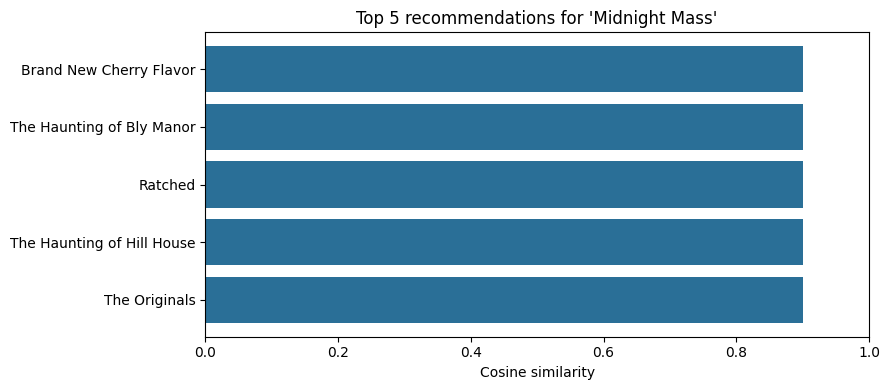

In [8]:
# Visualize the recommendations for one title
query = "Midnight Mass"
results = recommend(query, 5)

plt.figure(figsize=(9, 4))
plt.barh(results["title"], results["similarity"], color="#2a6f97")
plt.xlabel("Cosine similarity")
plt.title(f"Top 5 recommendations for '{query}'")
plt.xlim(0, 1)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 5. Evaluate recommendation quality

There are no user ratings in this dataset, so we cannot compute classic recommender metrics. Instead we use an **indirect check**: a good recommender should suggest titles with the same maturity `rating` (TV-MA, PG, ...) as the original title.

To keep the test fair, `rating` is **not** used in the features. We compare three things:
- **Random baseline:** what we would get by picking titles at random
- **Genres only:** a simple model
- **Genres + director + country + type:** our model

In [9]:
ratings = df["rating"].to_numpy().astype(str)

def same_rating_at_k(matrix, k=5, chunk=1000):
    """Average share of the top-k recommendations that have the same rating as the source title."""
    hits, total = 0, 0
    for start in range(0, matrix.shape[0], chunk):
        end = min(start + chunk, matrix.shape[0])
        scores = cosine_similarity(matrix[start:end], matrix).round(6)
        for row, i in enumerate(range(start, end)):
            scores[row, i] = -1
            order = np.lexsort((np.abs(years - years[i]), -scores[row]))[:k]
            hits += (ratings[order] == ratings[i]).sum()
            total += k
    return hits / total

# Random baseline: probability that two random titles share the same rating
p = df["rating"].value_counts(normalize=True)
baseline = float((p ** 2).sum())

# Genres-only model
genres_only = df.apply(lambda r: build_features(r, use_director=False, use_country=False, use_type=False), axis=1)
genres_matrix = TfidfVectorizer(token_pattern=r"\S+").fit_transform(genres_only)

evaluation = pd.DataFrame({
    "Model": ["Random baseline", "Genres only", "Genres + director + country + type"],
    "Same rating in top 5": [baseline, same_rating_at_k(genres_matrix), same_rating_at_k(feature_matrix)],
})
evaluation["Same rating in top 5"] = (evaluation["Same rating in top 5"] * 100).round(1).astype(str) + " %"
evaluation

,Model,Same rating in top 5
0,Random baseline,21.9 %
1,Genres only,42.2 %
2,Genres + director + country + type,41.8 %
